# Diabetes Challenge

Your task today is to **analyze** the Kaggle "Pima Indians Diabetes Database" and to **predict** whether a patient has Diabetes or not.

## Task:
- Load the data from the database. The schema is called `diabetes`. To connect to the database you need to copy the `.env` file from the visualization or hands-on-ml repository into this repo. Explore the database, try to establish what the relationships between the tables are (1-1, 1-N, N-M). Explain to yourself and the group what data do you see and whether it makes sense. What JOINs are appropriate to use and why? 
- Use at least two different classification algorithms we have learned so far to predict Diabetes patients. 
- Discuss before you start with the modeling process which **evaluation metric** you choose and explain why.
- Implement a GridSearchCV or RandomizedSearchCV to tune the hyperparameters of your model.
- **Optional:** If you have time at the end, try to use sklearn's pipline module to encapsulate all the steps into a pipeline.

Don't forget to split your data in train and test set. And analyze your final model on the test data. It might also be necessary to scale your data in order to improve the performance of some of the models.


## Helpful links and advise:
- [sklearn documentation on hyperparameter tuning](https://scikit-learn.org/stable/modules/grid_search.html#grid-search)
- It might be helpful to check some sources on how to deal with imbalanced data. 
    * [8 Tactics to Combat Imbalanced Classes](https://machinelearningmastery.com/tactics-to-combat-imbalanced-classes-in-your-machine-learning-dataset/)
    * [Random-Oversampling/Undersampling](https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/)


# Data Description

## Context
This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

## Acknowledgements
Smith, J.W., Everhart, J.E., Dickson, W.C., Knowler, W.C., & Johannes, R.S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. In Proceedings of the Symposium on Computer Applications and Medical Care (pp. 261--265). IEEE Computer Society Press.

## About this dataset
The datasets consist of several medical predictor (independent) variables and one target (dependent) variable, Outcome. Independent variables include the number of pregnancies the patient has had, their BMI, insulin level, age, and so on. For the outcome class value 1 is interpreted as "tested positive for diabetes".

|Column Name| Description|
|:------------|:------------|
|Pregnancies|Number of times pregnant|
|Glucose|Plasma glucose concentration a 2 hours in an oral glucose tolerance test|
|BloodPressure|Diastolic blood pressure (mm Hg)|
|SkinThickness|Triceps skin fold thickness (mm)|
|Insulin|2-Hour serum insulin (mu U/ml)|
|BMI|Body mass index (weight in kg/(height in m)^2)|
|DiabetesPedigreeFunction| Diabetes pedigree function|
|Age| Age (years)|
|Outcome|Class variable (0 or 1) |

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Libraries for data import
import os
from sqlalchemy import create_engine
from dotenv import load_dotenv

# Preprocessing
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import recall_score, accuracy_score, precision_score
from sklearn.metrics import classification_report, confusion_matrix, roc_curve
from sklearn.metrics import fbeta_score, make_scorer


# Define a plotting style to be used for all plots in this notebook
plt.style.use('tableau-colorblind10')

In [2]:
# Read the database connection string from the .env file
load_dotenv()

DB_STRING = os.getenv('DB_STRING')
db = create_engine(DB_STRING)

In [3]:
# Pull the data straight from the database, joining the tables on the patient id
query_string = """
SET schema 'diabetes';

SELECT *
FROM patient p
LEFT JOIN blood_metrics bd ON p.id = bd.patientid
LEFT JOIN skin s ON p.id = s.patientid
LEFT JOIN pedigree_outcome po ON p.id = po.PatientId
WHERE bd.measurement_date = '2022-12-13';
"""

df = pd.read_sql(query_string, db)

In [4]:
# A SELECT * across the joins brings in the join keys (id, patientid) and the
# measurement_date column, and Postgres lower-cases the names. Drop the keys and
# restore the feature names the rest of the notebook expects.
df = df.drop(columns=['id', 'patientid', 'measurement_date'])
df = df.rename(columns={
    'pregnancies': 'Pregnancies',
    'glucose': 'Glucose',
    'bloodpressure': 'BloodPressure',
    'skinthickness': 'SkinThickness',
    'insulin': 'Insulin',
    'bmi': 'BMI',
    'diabetespedigreefunction': 'DiabetesPedigreeFunction',
    'outcome': 'Outcome',
})

In [5]:
# Optional: cache the data locally so you do not have to query the database every run
df.to_csv('data/diabetes.csv', index=False)

In [6]:
df.head(5)

,Age,Pregnancies,BMI,Insulin,Glucose,BloodPressure,SkinThickness,DiabetesPedigreeFunction,Outcome
0,50,6,33.6,0,148,72,35,0.627,1
1,31,1,26.6,0,85,66,29,0.351,0
2,32,8,23.3,0,183,64,0,0.672,1
3,21,1,28.1,94,89,66,23,0.167,0
4,33,0,43.1,168,137,40,35,2.288,1


In [7]:
#Print the shape of the data
print('Diabetes dataset')
print('==================')
print(f"Samples: {df.shape[0]}")
print(f"Features: {df.shape[1]-1}")
df.info()

Diabetes dataset
Samples: 768
Features: 8
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       768 non-null    int64  
 1   Pregnancies               768 non-null    int64  
 2   BMI                       768 non-null    float64
 3   Insulin                   768 non-null    int64  
 4   Glucose                   768 non-null    int64  
 5   BloodPressure             768 non-null    int64  
 6   SkinThickness             768 non-null    int64  
 7   DiabetesPedigreeFunction  768 non-null    float64
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df.describe()

,Age,Pregnancies,BMI,Insulin,Glucose,BloodPressure,SkinThickness,DiabetesPedigreeFunction,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,33.240885,3.845052,31.992578,79.799479,120.894531,69.105469,20.536458,0.471876,0.348958
std,11.760232,3.369578,7.884160,115.244002,31.972618,19.355807,15.952218,0.331329,0.476951
min,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,0.000000
25%,24.000000,1.000000,27.300000,0.000000,99.000000,62.000000,0.000000,0.243750,0.000000
50%,29.000000,3.000000,32.000000,30.500000,117.000000,72.000000,23.000000,0.372500,0.000000
75%,41.000000,6.000000,36.600000,127.250000,140.250000,80.000000,32.000000,0.626250,1.000000
max,81.000000,17.000000,67.100000,846.000000,199.000000,122.000000,99.000000,2.420000,1.000000


In [9]:
df.isnull().sum()

Age                         0
Pregnancies                 0
BMI                         0
Insulin                     0
Glucose                     0
BloodPressure               0
SkinThickness               0
DiabetesPedigreeFunction    0
Outcome                     0
dtype: int64

In [10]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']

print(X.shape)   # (n_rows, 8)  -> 2 numbers = 2D
print(y.shape)   # (n_rows,)    -> 1 number  = 1D

(768, 8)
(768,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")
print(f"Features: {X_train.shape[1]}")
print(f"Target train: {y_train.value_counts()}")
print(f"Target test: {y_test.value_counts()}")

Training samples: 537
Testing samples: 231
Features: 8
Target train: Outcome
0    350
1    187
Name: count, dtype: int64
Target test: Outcome
0    150
1     81
Name: count, dtype: int64


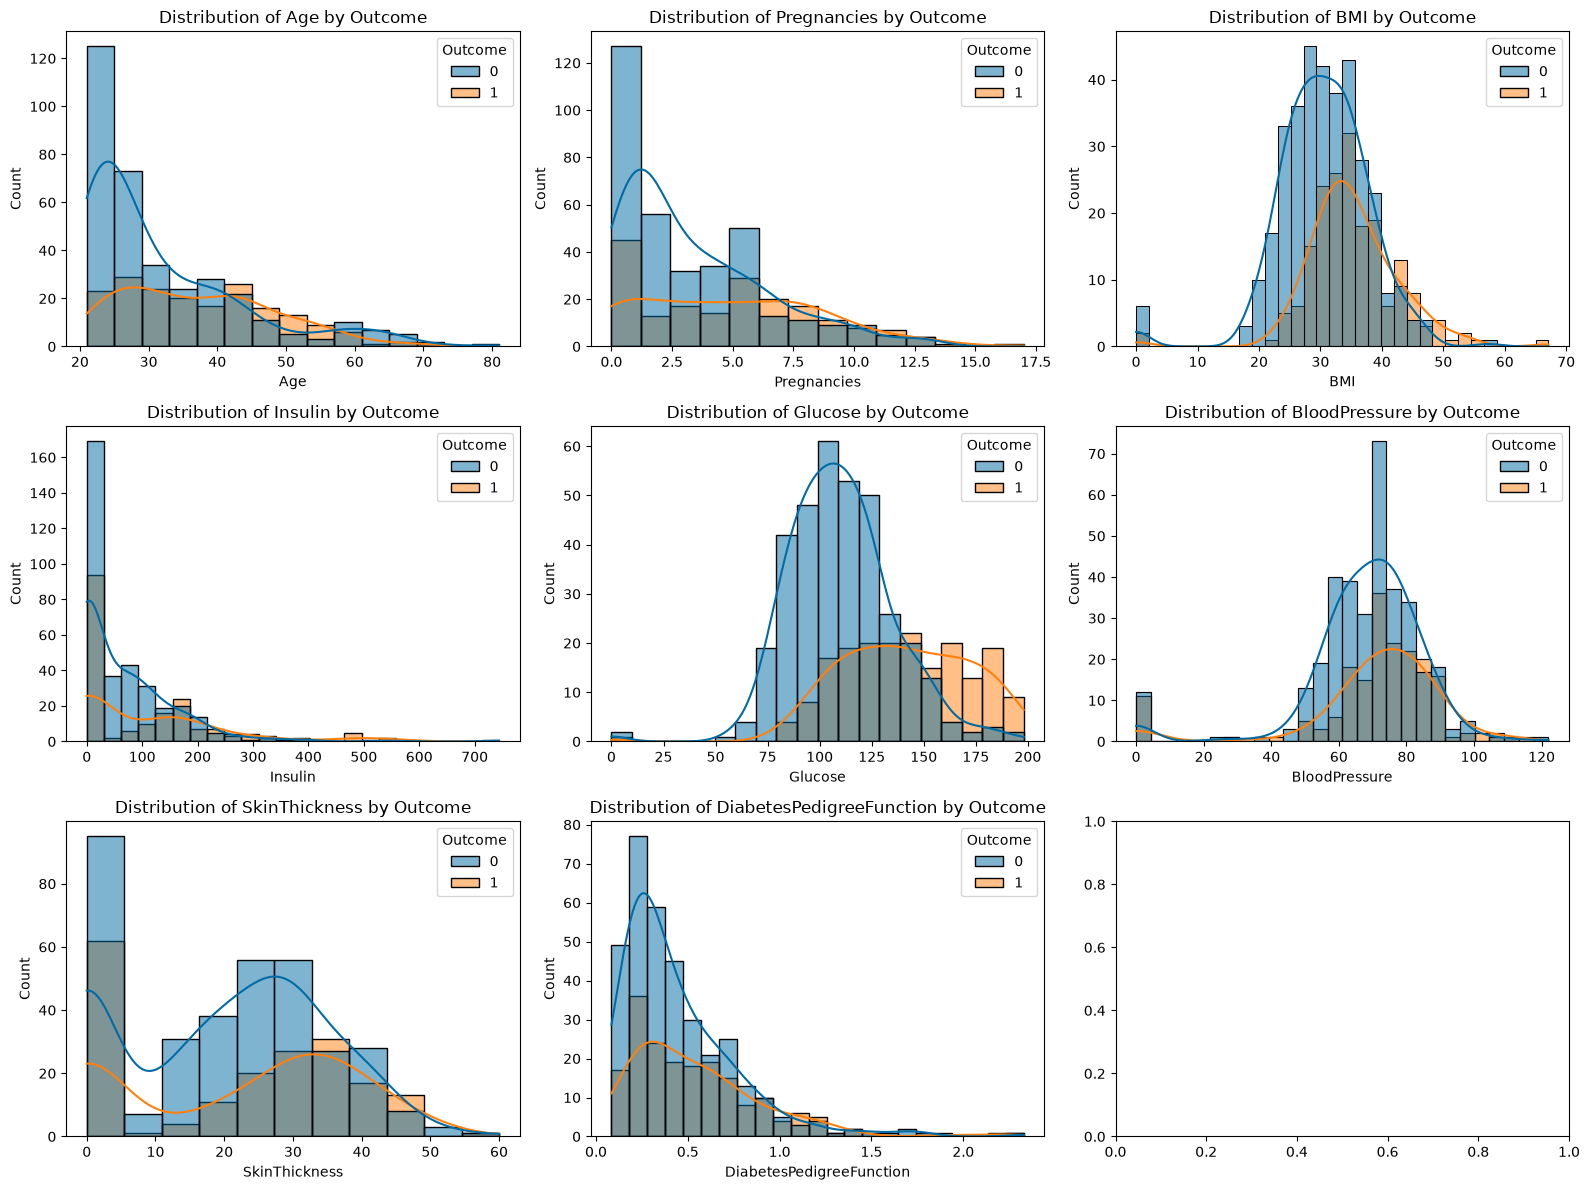

In [12]:
# Plot distribution of features in the training set:
fig, ax = plt.subplots(3, 3, figsize=(16, 12))
for i, col in enumerate(X_train.columns):
    sns.histplot(data=X_train, x=col, hue=y_train, ax=ax[i//3, i%3], kde=True)
    ax[i//3, i%3].set_title(f'Distribution of {col} by Outcome')
fig.tight_layout()

* The features `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI` include zeros, even if it is not a expected value for those features. This might indicate, that missing values are represented as zeros in this dataset. We have to find a suitable strategy to replace/impute those values. 

In [13]:
def replace_zeros_with_nan(df, columns):
    """
    Replace zeros with NaN in specified columns of a DataFrame.

    Parameters:
    df (pd.DataFrame): The input DataFrame.
    columns (list): List of column names where zeros should be replaced with NaN.

    Returns:
    pd.DataFrame: DataFrame with zeros replaced by NaN in specified columns.
    """
    cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
    for col in columns:
        if col in cols_with_zeros:
            df[col] = df[col].replace(0, np.nan)
    return df


X_train = replace_zeros_with_nan(X_train, X_train.columns)

In [14]:
X_train.isna().sum()

Age                           0
Pregnancies                   0
BMI                           8
Insulin                     256
Glucose                       3
BloodPressure                23
SkinThickness               157
DiabetesPedigreeFunction      0
dtype: int64

In [15]:
print(X_train.query("BMI.isnull() & BloodPressure.isnull()").shape[0]) # .query() is a pandas DataFrame method for filtering.
index_list = X_train.query("BMI.isnull() & BloodPressure.isnull()").index.tolist()
X_train.query("BMI.isnull() & BloodPressure.isnull()")


5


,Age,Pregnancies,BMI,Insulin,Glucose,BloodPressure,SkinThickness,DiabetesPedigreeFunction
60,21,2,NaN,NaN,84.0,NaN,NaN,0.304
426,25,0,NaN,NaN,94.0,NaN,NaN,0.256
706,30,10,NaN,NaN,115.0,NaN,NaN,0.261
522,26,6,NaN,NaN,114.0,NaN,NaN,0.189
49,24,7,NaN,NaN,105.0,NaN,NaN,0.305


In [16]:
# Drop rows by index
X_train = X_train.drop(index=index_list)

In [17]:
X_train.query("BMI.isnull() & BloodPressure.isnull()")

,Age,Pregnancies,BMI,Insulin,Glucose,BloodPressure,SkinThickness,DiabetesPedigreeFunction


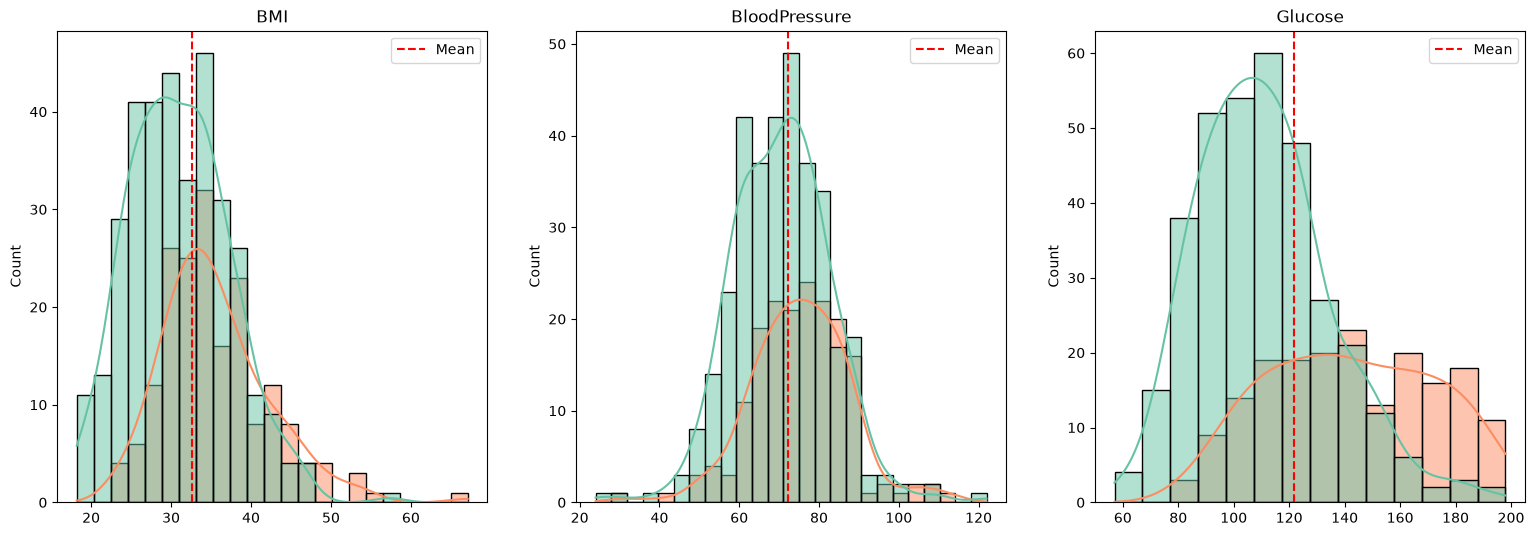

In [18]:
# Plot distribution of numerical features with missing values 
col_plot = ["BMI", "BloodPressure", "Glucose"]
fig, ax = plt.subplots(1, 3, figsize=(16, 6))

for count, col in enumerate(col_plot):
    sns.histplot(data=X_train, x=col, hue=y_train, ax=ax[count], kde=True, palette='Set2').set(title=col, xlabel='')
    ax[count].axvline(X_train[col].mean(), color="red", linestyle="--", label="Mean")
    ax[count].legend()

fig.tight_layout(pad=3)

In [19]:
# Print mean and median for those features
print(f"Mean value: {X_train[col_plot].mean().round(2)}")
print(f"\nMedian value: {X_train[col_plot].median().round(2)}")

Mean value: BMI               32.62
BloodPressure     72.24
Glucose          121.77
dtype: float64

Median value: BMI               32.4
BloodPressure     72.0
Glucose          117.0
dtype: float64


In [20]:
X_train[col_plot] = X_train[col_plot].fillna(X_train[col_plot].median())

In [21]:
X_train.isna().sum()

Age                           0
Pregnancies                   0
BMI                           0
Insulin                     251
Glucose                       0
BloodPressure                 0
SkinThickness               152
DiabetesPedigreeFunction      0
dtype: int64

In [22]:
# We should also drop those 5 rows from y_train to keep the same number of rows in both X_train and y_train. 
# Otherwise, we will get an error when we try to fit a model.
y_train = y_train.loc[X_train.index]
print(X_train.shape, y_train.shape)   # both should show 532 rows

(532, 8) (532,)


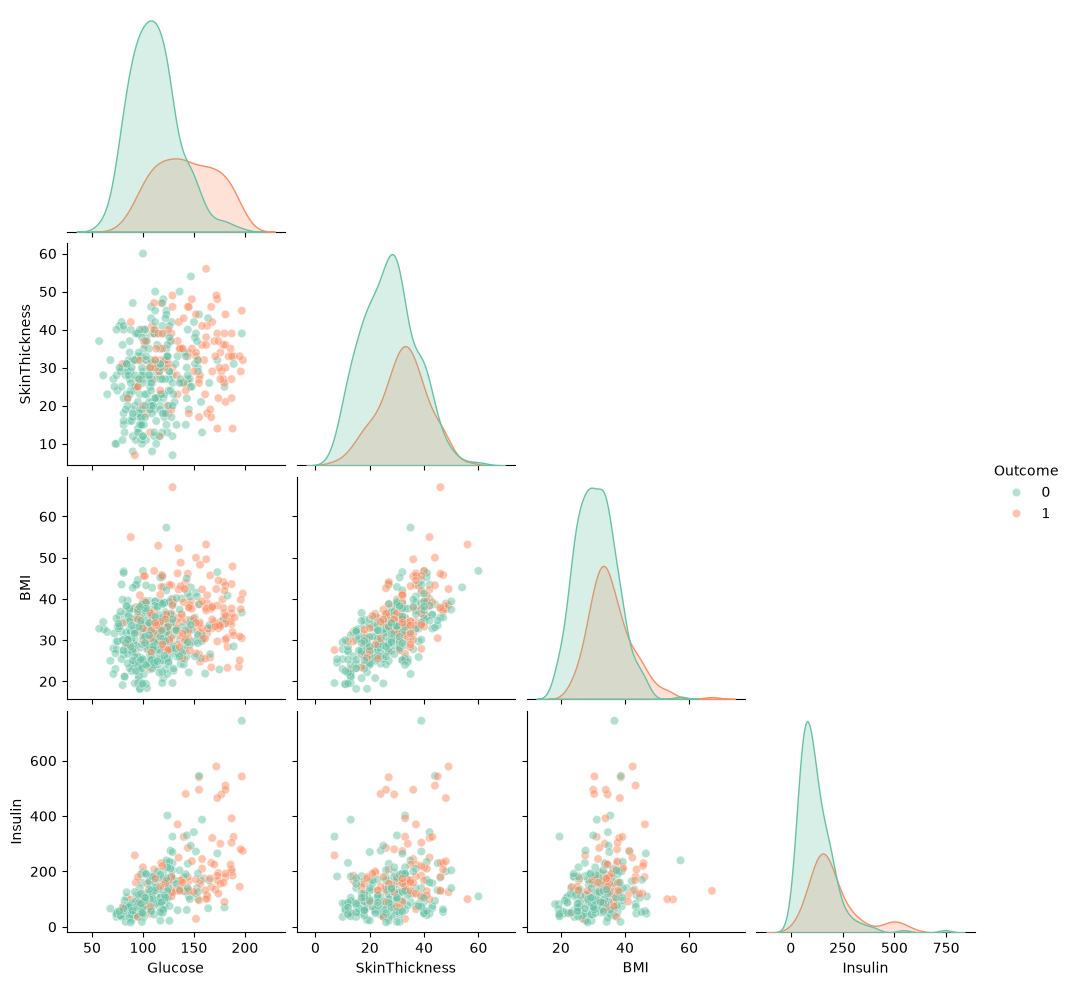

In [23]:

plot_df = X_train[["Glucose", "SkinThickness", "BMI", "Insulin"]].assign(Outcome=y_train)

sns.pairplot(plot_df, hue="Outcome", palette='Set2', 
             diag_kind='kde', plot_kws={'alpha':0.5}, corner=True)
# pairplot only accepts column name only!
fig.tight_layout()

<Axes: >

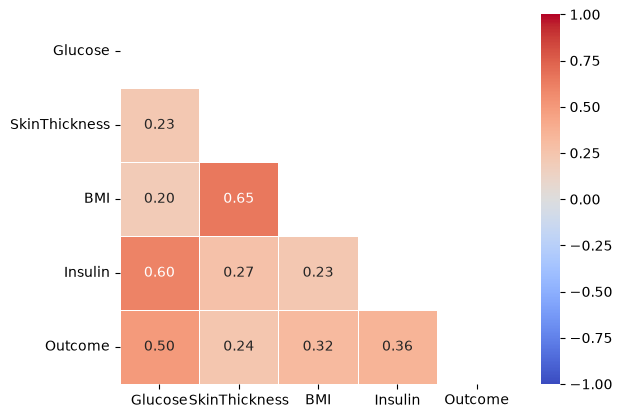

In [24]:
mask = np.triu(np.ones_like(plot_df.corr(), dtype=bool))
sns.heatmap(plot_df.corr(), mask=mask, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

In [25]:
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

imputer = IterativeImputer(
    estimator=RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1),
    max_iter=30,
    tol=1e-2,
    random_state=42,
    add_indicator=True,   # appends missing-flag columns automatically
)

# RandomForestRegressor lives inside the imputer. Its only job is to predict the missing Insulin and SkinThickness values.


In [26]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

pipe = make_pipeline(imputer, RandomForestClassifier(random_state=42, n_jobs=-1))
print(cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc").mean())

# RandomForestClassifier is the final model. It predicts Outcome after the imputer has filled the gaps.

/Users/maryamsajedi/Desktop/Materials/ml-diabetes_challenge/.venv/lib/python3.13/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


0.8019065878562446


In [27]:
X_test.head(5)

,Age,Pregnancies,BMI,Insulin,Glucose,BloodPressure,SkinThickness,DiabetesPedigreeFunction
730,34,3,28.4,79,130,78,23,0.323
198,26,4,34.8,99,109,64,44,0.905
24,51,11,36.6,146,143,94,33,0.254
417,37,4,38.5,0,144,82,32,0.554
387,45,8,43.3,0,105,100,36,0.239


In [28]:
X_test = replace_zeros_with_nan(X_test, X_test.columns)
X_test.isna().sum()

Age                           0
Pregnancies                   0
BMI                           3
Insulin                     118
Glucose                       2
BloodPressure                12
SkinThickness                70
DiabetesPedigreeFunction      0
dtype: int64

In [29]:
print(X_test.query("BMI.isnull() & BloodPressure.isnull()").shape[0]) # .query() is a pandas DataFrame method for filtering.
index_list_test = X_test.query("BMI.isnull() & BloodPressure.isnull()").index.tolist()
print(X_test.query("BMI.isnull() & BloodPressure.isnull()"))


2
     Age  Pregnancies  BMI  Insulin  Glucose  BloodPressure  SkinThickness  \
494   22            3  NaN      NaN     80.0            NaN            NaN   
81    22            2  NaN      NaN     74.0            NaN            NaN   

     DiabetesPedigreeFunction  
494                     0.174  
81                      0.102  


In [30]:
X_test, y_test = X_test.drop(index=index_list_test), y_test.drop(index=index_list_test)

In [33]:
col_plot = ["BMI", "BloodPressure", "Glucose"]

# Compute from train (ideally saved before you filled the train NaNs; see note below)
train_medians = X_train[col_plot].median()

X_test = X_test.copy()
X_test[col_plot] = X_test[col_plot].fillna(train_medians)

In [34]:
X_test.isnull().sum()

Age                           0
Pregnancies                   0
BMI                           0
Insulin                     116
Glucose                       0
BloodPressure                 0
SkinThickness                68
DiabetesPedigreeFunction      0
dtype: int64

In [38]:
assert list(X_test.columns) == list(X_train.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)

In [ ]:
imputer = IterativeImputer(
    estimator=RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                    n_jobs=-1, random_state=42),
    max_iter=30, tol=1e-2, random_state=42, add_indicator=True,
)

imputer.fit(X_train)
# This learns, from training rows only, how to predict Insulin and SkinThickness from the other columns. X_test is not involved.

,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",RandomForestR...ndom_state=42)
,"max_iter max_iter: int, default=10Maximum number of imputation rounds to perform before returning theimputations computed during the final round. A round is a singleimputation of each feature with missing values. The stopping criterionis met once `max(abs(X_t - X_{t-1}))/max(abs(X[known_vals])) < tol`,where `X_t` is `X` at iteration `t`. Note that early stopping is onlyapplied if `sample_posterior=False`.",30
,"tol tol: float, default=1e-3Tolerance of the stopping condition.",0.01
,"random_state random_state: int, RandomState instance or None, default=NoneThe seed of the pseudo random number generator to use. Randomizesselection of estimator features if `n_nearest_features` is not `None`,the `imputation_order` if `random`, and the sampling from posterior if`sample_posterior=True`. Use an integer for determinism.See :term:`the Glossary <random_state>`.",42
,"add_indicator add_indicator: bool, default=FalseIf `True`, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",True
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan
,"sample_posterior sample_posterior: bool, default=FalseWhether to sample from the (Gaussian) predictive posterior of thefitted estimator for each imputation. Estimator must support`return_std` in its `predict` method if set to `True`. Set to`True` if using `IterativeImputer` for multiple imputations.",False
,"n_nearest_features n_nearest_features: int, default=NoneNumber of other features to use to estimate the missing values ofeach feature column. Nearness between features is measured usingthe absolute correlation coefficient between each feature pair (afterinitial imputation). To ensure coverage of features throughout theimputation process, the neighbor features are not necessarily nearest,but are drawn with probability proportional to correlation for eachimputed target feature. Can provide significant speed-up when thenumber of features is huge. If `None`, all features will be used.",None
,"initial_strategy initial_strategy: {'mean', 'median', 'most_frequent', 'constant'}, default='mean'Which strategy to use to initialize the missing values. Same as the`strategy` parameter in :class:`~sklearn.impute.SimpleImputer`.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen `strategy=""constant""`, `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types... versionadded:: 1.3",None
,"imputation_order imputation_order: {'ascending', 'descending', 'roman', 'arabic', 'random'}, default='ascending'The order in which the features will be imputed. Possible values:- `'ascending'`: From features with fewest missing values to most.- `'descending'`: From features with most missing values to fewest.- `'roman'`: Left to right.- `'arabic'`: Right to left.- `'random'`: A random order for each round.",'ascending'


In [ ]:
# Sk-learn always return a numpy array, so the column names and index will be lost. 
# We need to restore them back in DataFrame format in the next step:
cols = imputer.get_feature_names_out(X_train.columns)   # original columns + missingindicator flags

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=cols, index=X_train.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=cols, index=X_test.index)

In [ ]:
from sklearn.metrics import roc_auc_score

pipe = make_pipeline(imputer, RandomForestClassifier(random_state=42, n_jobs=-1))
pipe.fit(X_train, y_train)

y_proba = pipe.predict_proba(X_test)[:, 1]
print("Test ROC AUC:", roc_auc_score(y_test, y_proba))